In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    PrecisionRecallDisplay,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibrationDisplay

RANDOM_STATE = 42
DATA_PATH = Path("pret.csv")

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
df = df.dropna(subset=["nonPaye"]).copy()

target = "nonPaye"
X = df.drop(columns=[target])
y = df[target].astype(int)

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            categorical_features,
        ),
    ],
    remainder="drop",
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=250,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=RANDOM_STATE,
    )),
])

model.fit(X_train, y_train)
y_proba = model.predict_proba(X_test)[:, 1]

print(f"Dataset : {df.shape[0]:,} lignes | {X.shape[1]} variables")
print(f"Taux de défaut : {y.mean():.1%}")
print(f"Train : {len(X_train):,} | Test : {len(X_test):,}")
print(f"ROC-AUC : {roc_auc_score(y_test, y_proba):.3f}")
print(f"PR-AUC  : {average_precision_score(y_test, y_proba):.3f}")

FileNotFoundError: [Errno 2] No such file or directory: 'pret.csv'

# Prédiction du défaut de paiement

Le modèle cherche à repérer les dossiers présentant un risque de non-paiement. Le taux de défaut est minoritaire, ce qui rend la détection des dossiers risqués plus intéressante que la simple accuracy.

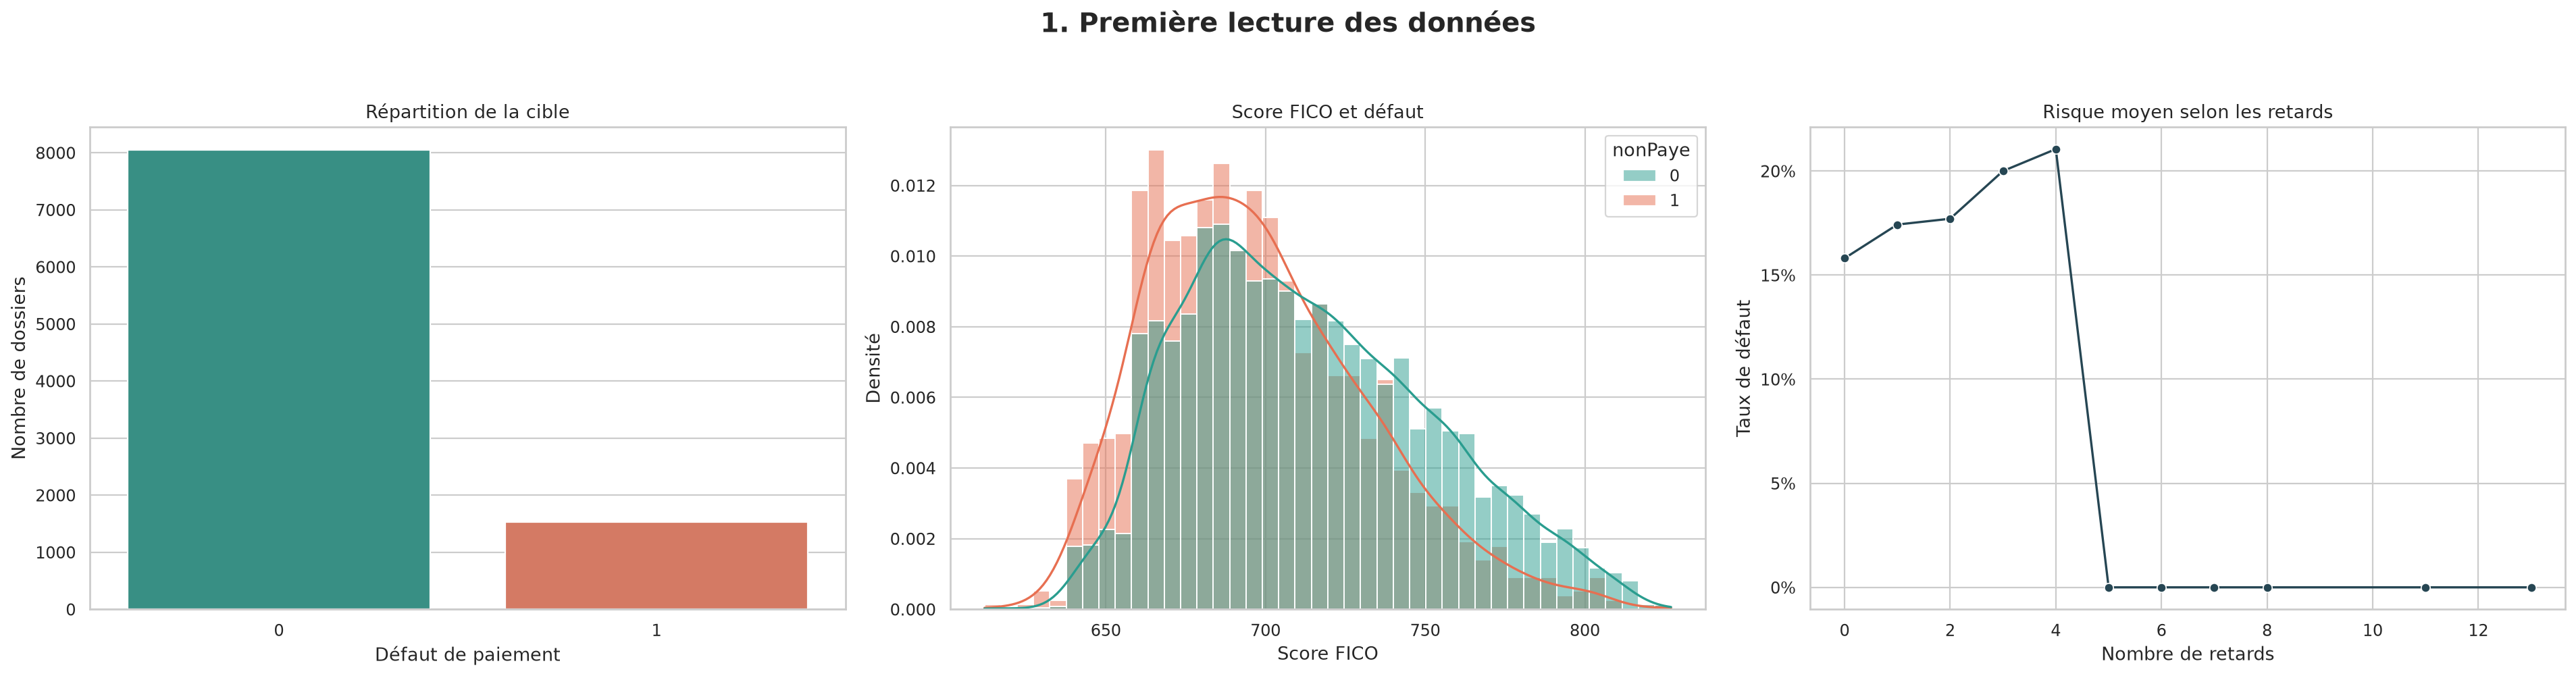

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 160
fig, axes = plt.subplots(1, 3, figsize=(24, 6))

sns.countplot(data=df, x=target, ax=axes[0], palette=["#2a9d8f", "#e76f51"])
axes[0].set_title("Répartition de la cible")
axes[0].set_xlabel("Défaut de paiement")
axes[0].set_ylabel("Nombre de dossiers")

sns.histplot(data=df, x="fico", hue=target, kde=True, stat="density", common_norm=False, ax=axes[1], palette=["#2a9d8f", "#e76f51"])
axes[1].set_title("Score FICO et défaut")
axes[1].set_xlabel("Score FICO")
axes[1].set_ylabel("Densité")

risk_by_term = df.groupby("nbreRetards", as_index=False)[target].mean()
sns.lineplot(data=risk_by_term, x="nbreRetards", y=target, marker="o", color="#264653", ax=axes[2])
axes[2].set_title("Risque moyen selon les retards")
axes[2].set_xlabel("Nombre de retards")
axes[2].set_ylabel("Taux de défaut")
axes[2].yaxis.set_major_formatter(lambda value, position: f"{value:.0%}")

plt.suptitle("1. Première lecture des données", fontsize=18, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

## Interprétation des performances

Le modèle distingue mieux les dossiers risqués qu’une décision aléatoire. Le seuil retenu privilégie la détection des défauts : il accepte donc davantage de fausses alertes pour éviter de laisser passer des dossiers réellement risqués.

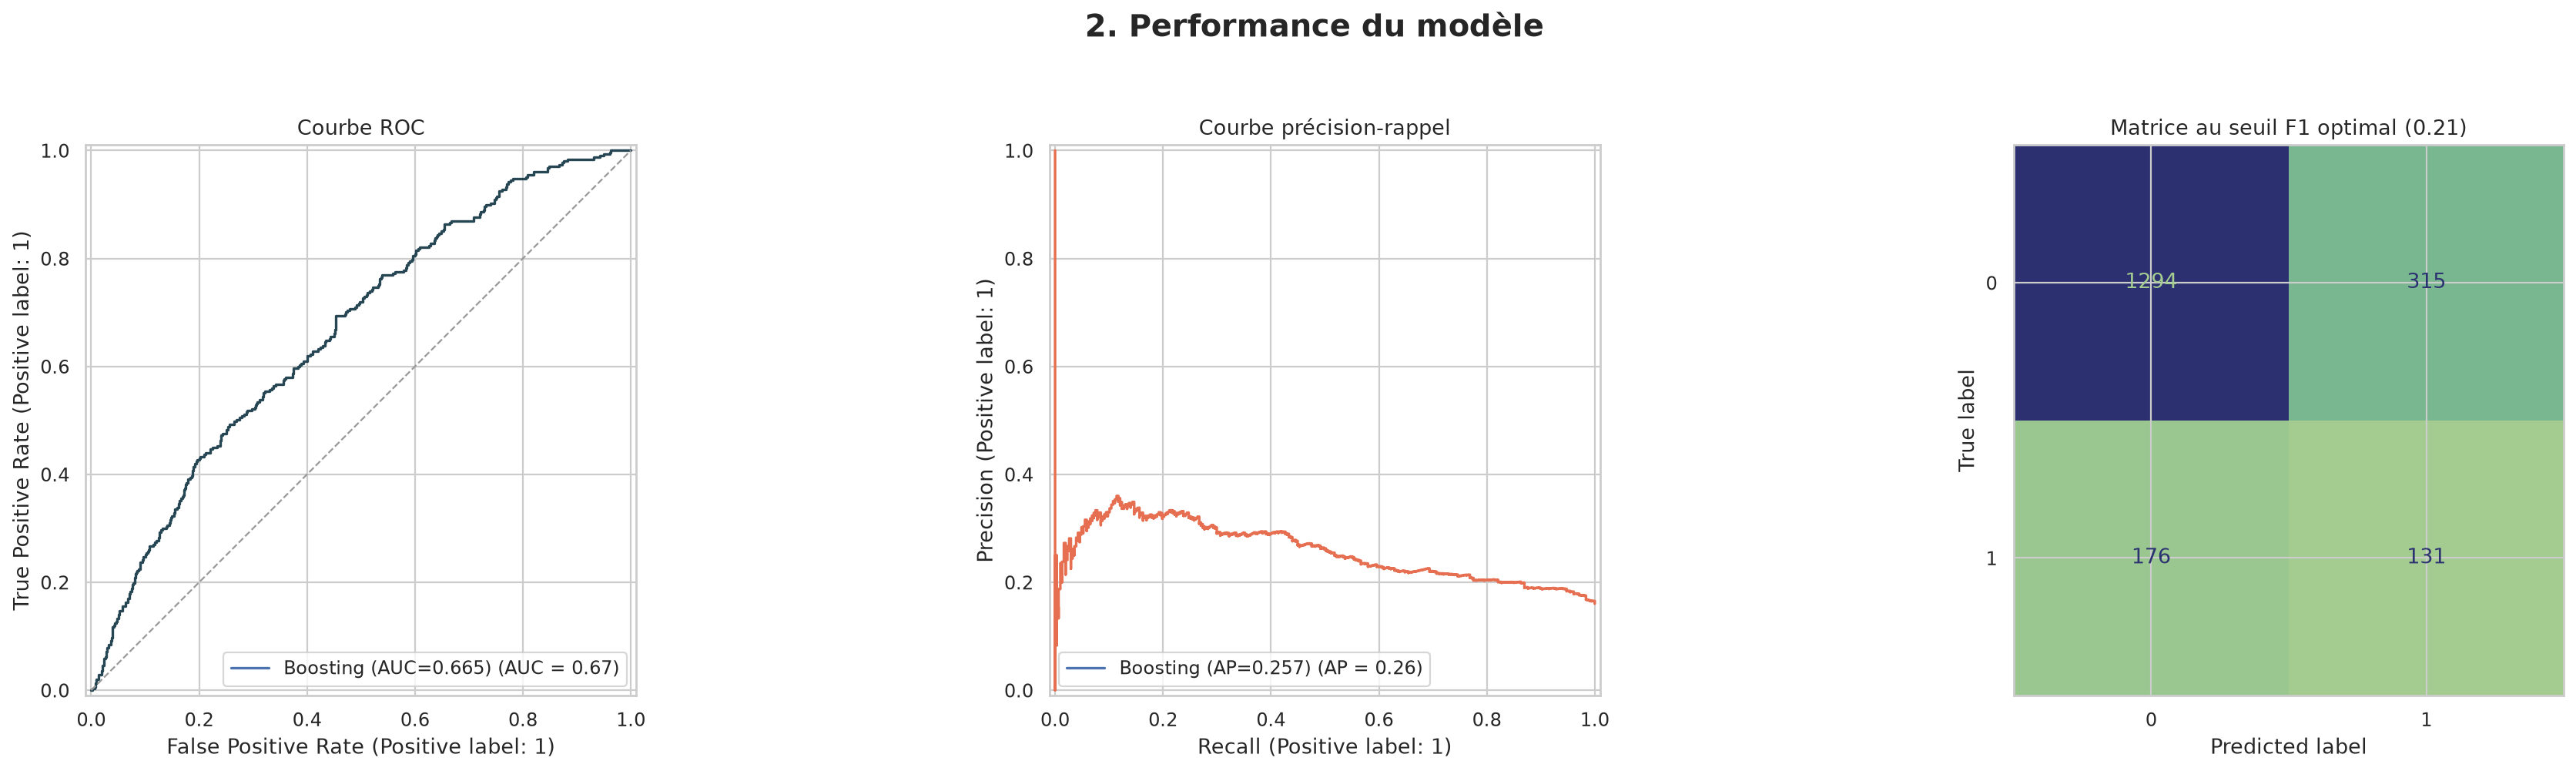

Seuil maximisant le F1 : 0.207
F1 : 0.348
              precision    recall  f1-score   support

  Non-défaut       0.88      0.80      0.84      1609
      Défaut       0.29      0.43      0.35       307

    accuracy                           0.74      1916
   macro avg       0.59      0.62      0.59      1916
weighted avg       0.79      0.74      0.76      1916



In [ ]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
f1_scores = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
best_index = int(np.argmax(f1_scores))
best_threshold = float(thresholds[best_index])
y_pred = (y_proba >= best_threshold).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(24, 6))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0], name=f"Boosting (AUC={roc_auc_score(y_test, y_proba):.3f})")
axes[0].lines[-1].set_color("#264653")
axes[0].plot([0, 1], [0, 1], "--", color="#999999", linewidth=1)
axes[0].set_title("Courbe ROC")

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=f"Boosting (AP={average_precision_score(y_test, y_proba):.3f})")
axes[1].lines[-1].set_color("#e76f51")
axes[1].set_title("Courbe précision-rappel")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[2], cmap="crest", colorbar=False)
axes[2].set_title(f"Matrice au seuil F1 optimal ({best_threshold:.2f})")

plt.suptitle("2. Performance du modèle", fontsize=18, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

print(f"Seuil maximisant le F1 : {best_threshold:.3f}")
print(f"F1 : {f1_score(y_test, y_pred):.3f}")
print(classification_report(y_test, y_pred, target_names=["Non-défaut", "Défaut"], zero_division=0))

## Interprétation des variables importantes

Les variables les plus influentes sont celles dont le mélange fait le plus baisser la qualité des prédictions. Le revenu annuel, l’objet du prêt, les réclamations et la mensualité semblent porter une grande partie du signal de risque.

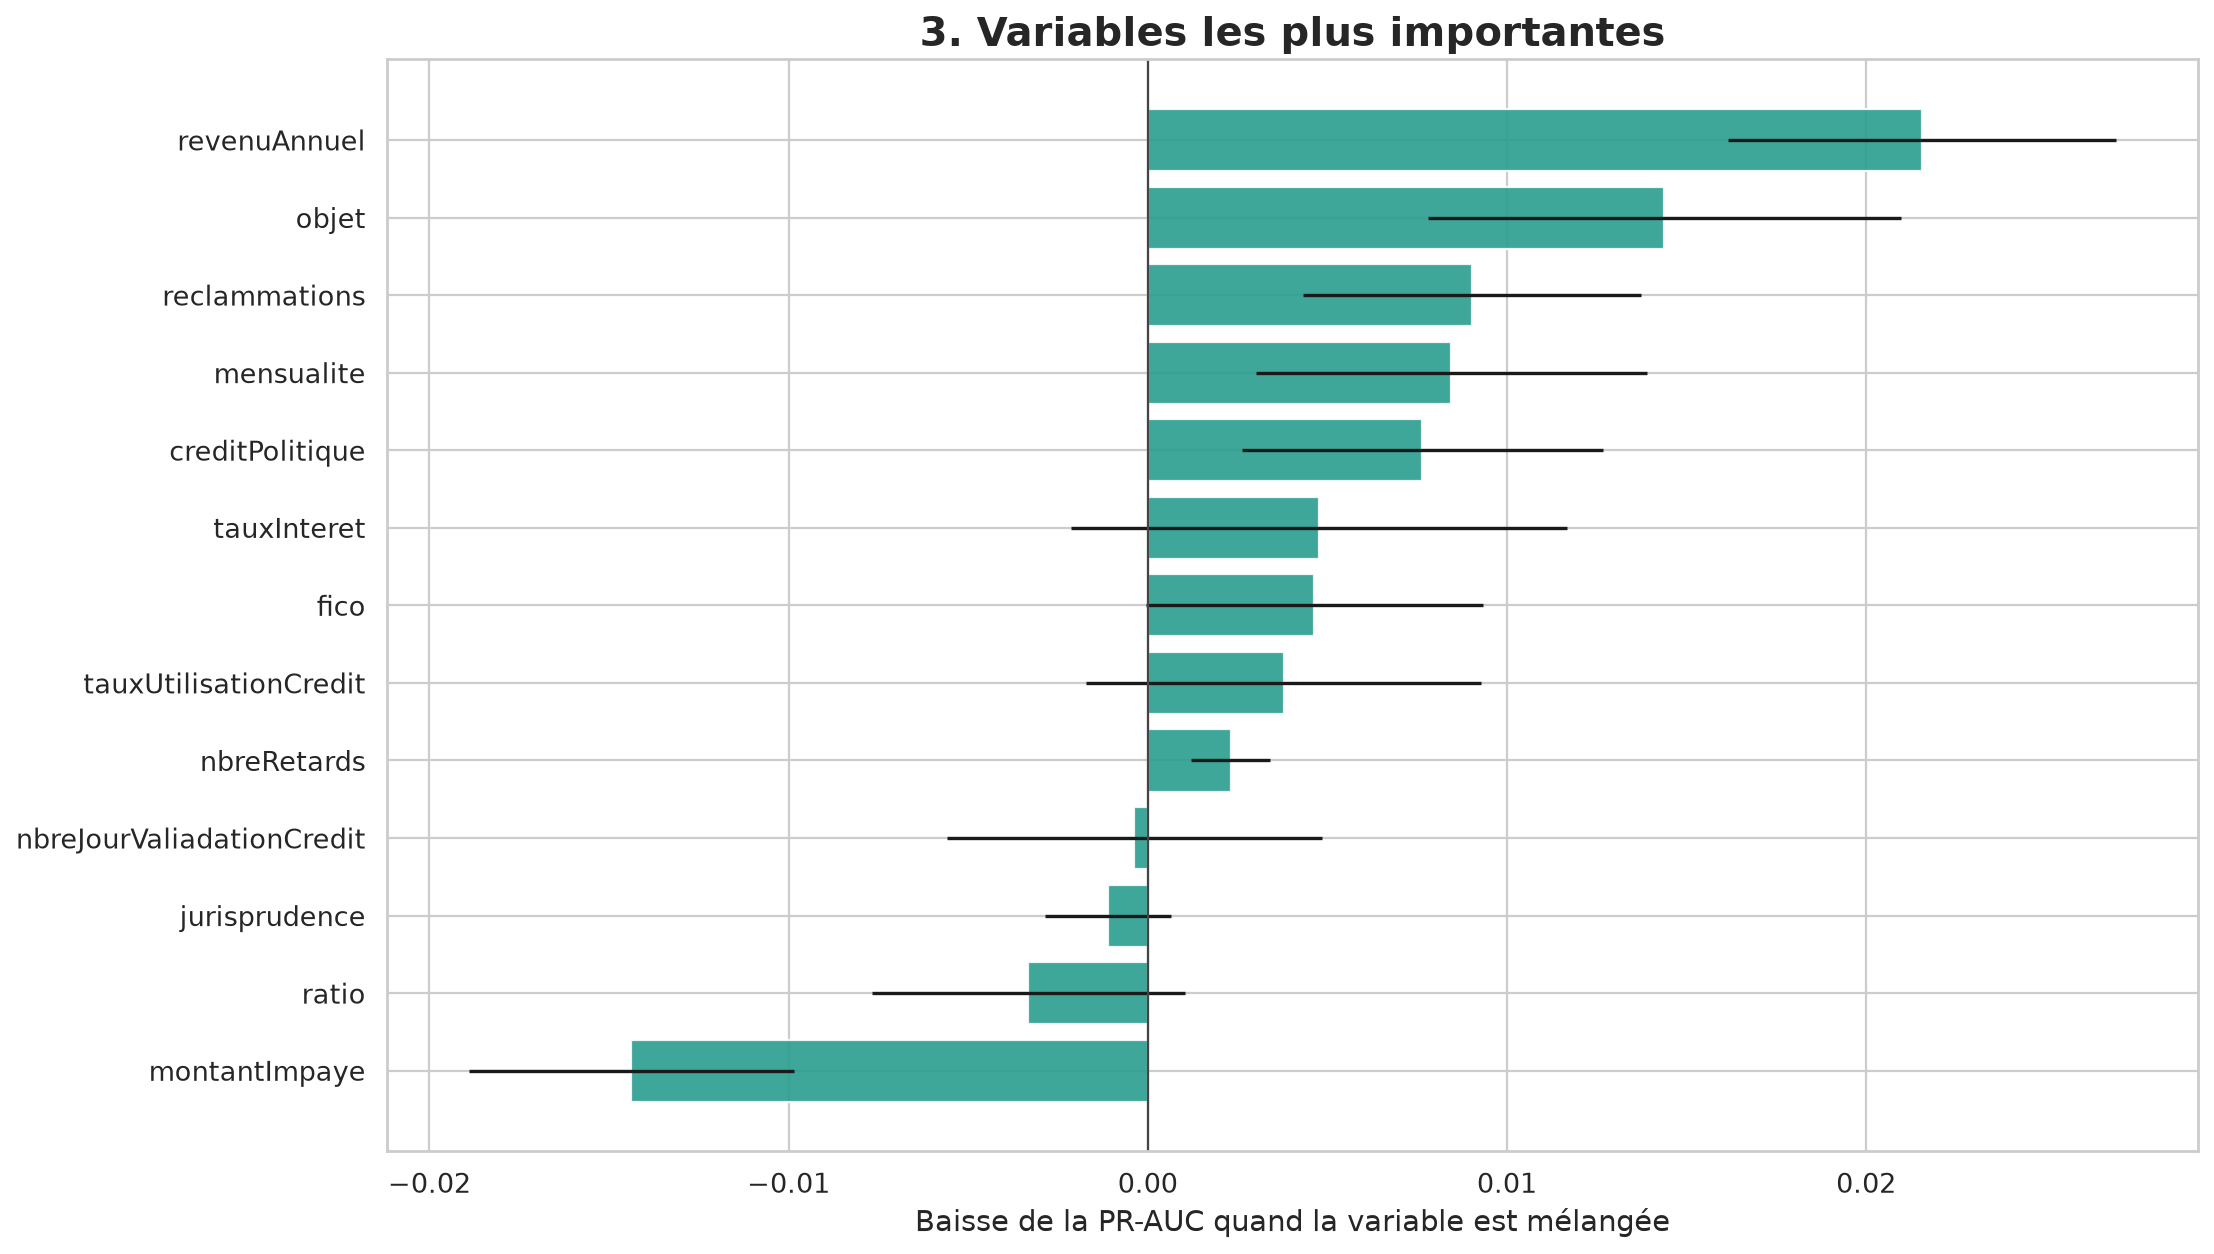

Variables les plus influentes :
       variable importance uncertainty
   revenuAnnuel     0.0216      0.0054
          objet     0.0144      0.0066
  reclammations     0.0090      0.0047
     mensualite     0.0085      0.0054
creditPolitique     0.0076      0.0050
    tauxInteret     0.0048      0.0069
           fico     0.0046      0.0047


In [ ]:
perm = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance = pd.DataFrame({
    "variable": X_test.columns,
    "importance": perm.importances_mean,
    "uncertainty": perm.importances_std,
}).sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(14, 8))
ax.barh(importance["variable"], importance["importance"], xerr=importance["uncertainty"], color="#2a9d8f", alpha=0.9)
ax.axvline(0, color="#444444", linewidth=1)
ax.set_title("3. Variables les plus importantes", fontsize=18, fontweight="bold")
ax.set_xlabel("Baisse de la PR-AUC quand la variable est mélangée", fontsize=13)
ax.set_ylabel("")
ax.tick_params(axis="both", labelsize=12)
plt.tight_layout()
plt.show()

print("Variables les plus influentes :")
print(importance.sort_values("importance", ascending=False).head(7).to_string(index=False, formatters={"importance": "{:.4f}".format, "uncertainty": "{:.4f}".format}))

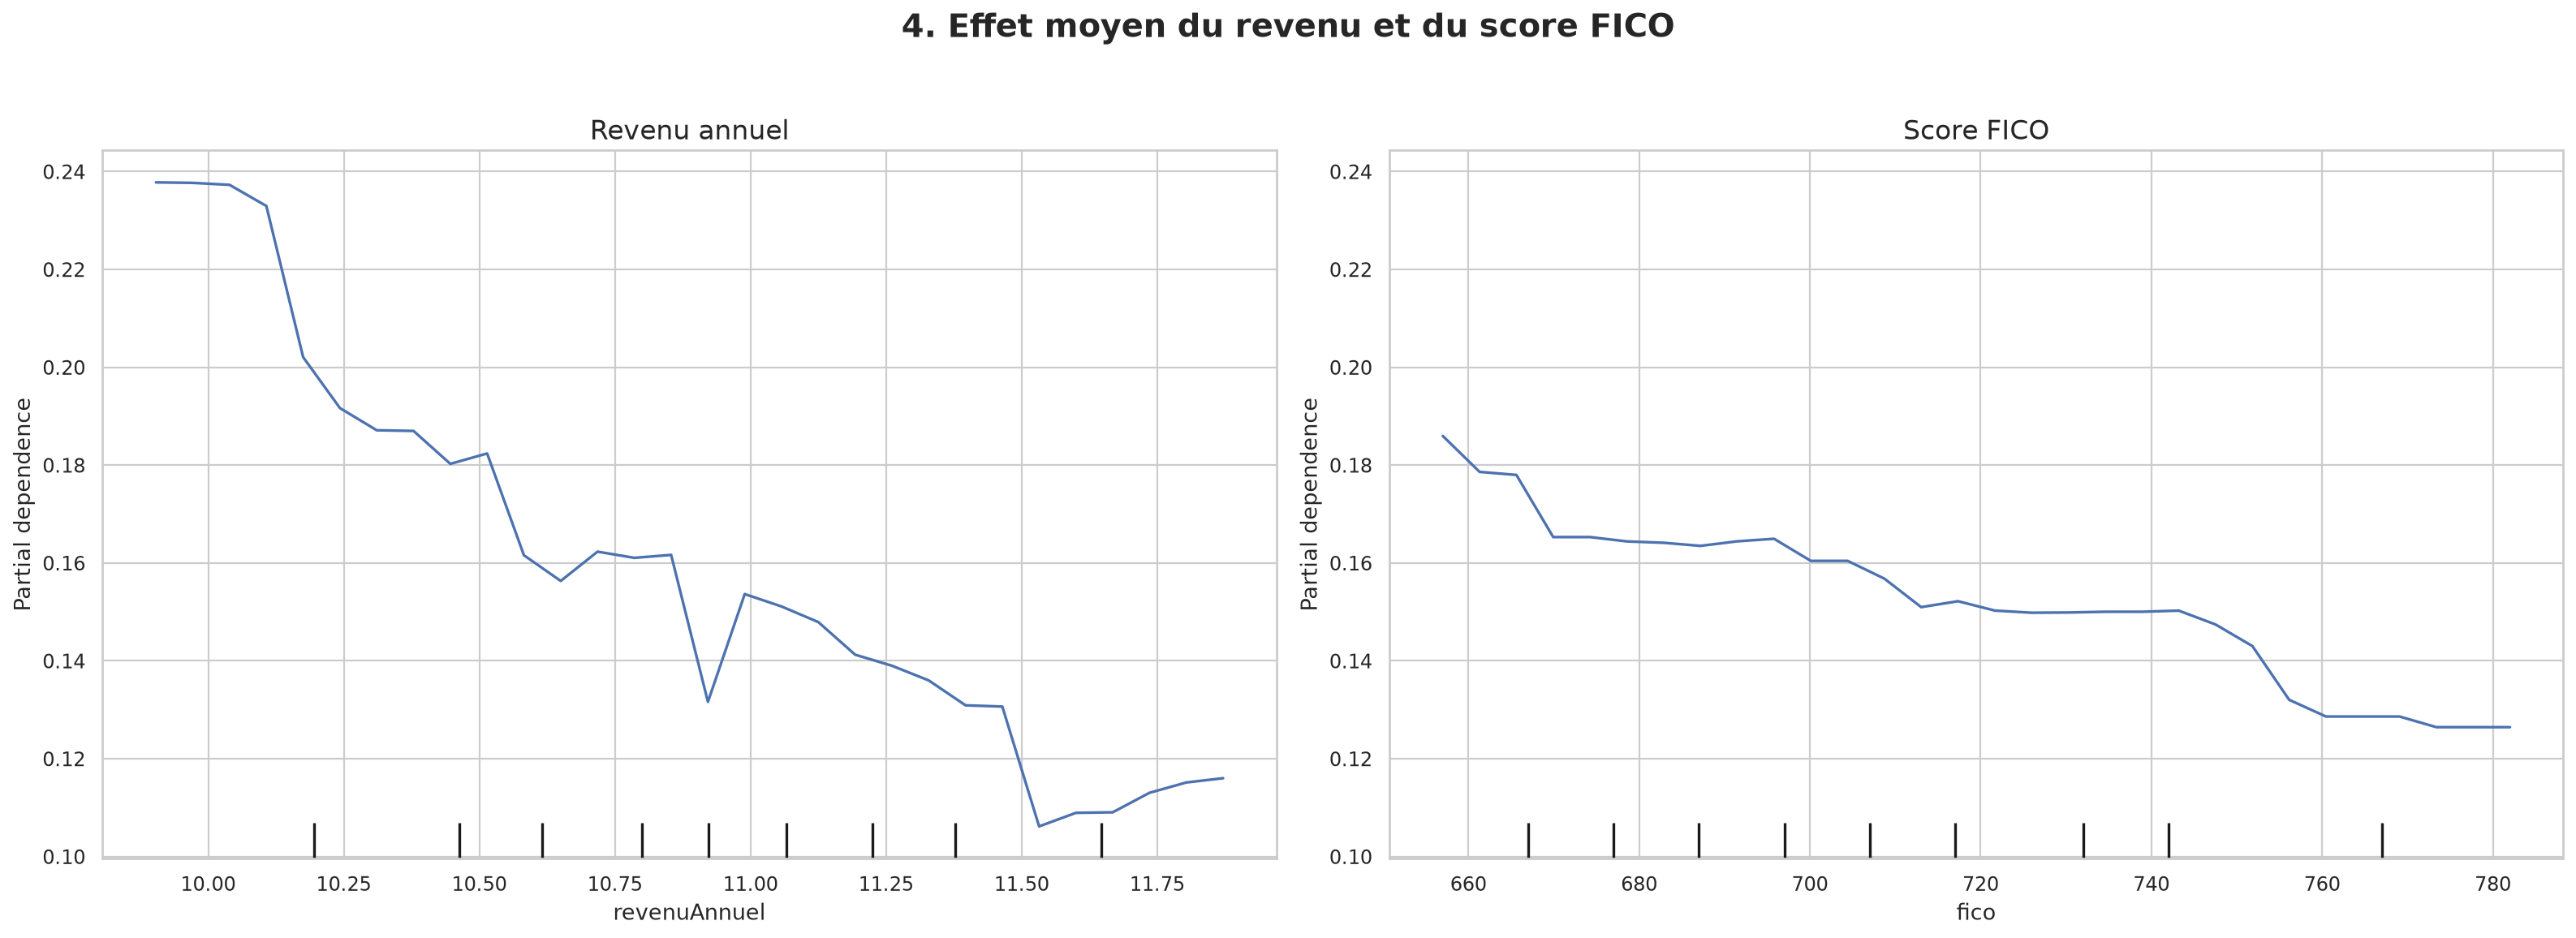

In [ ]:
X_test_pdp = X_test.copy()
X_test_pdp[numeric_features] = X_test_pdp[numeric_features].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
PartialDependenceDisplay.from_estimator(
    model,
    X_test_pdp,
    features=["revenuAnnuel", "fico"],
    kind="average",
    grid_resolution=30,
    ax=axes,
)
axes[0].set_title("Revenu annuel", fontsize=15)
axes[1].set_title("Score FICO", fontsize=15)
plt.suptitle("4. Effet moyen du revenu et du score FICO", fontsize=18, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## Interprétation d’un dossier à risque

Ce graphique montre les variables qui font augmenter ou diminuer le risque pour le dossier sélectionné. Les barres rouges augmentent la probabilité de défaut ; les barres vertes la diminuent. Ici, le montant impayé et l’objet du prêt sont les signaux les plus défavorables.

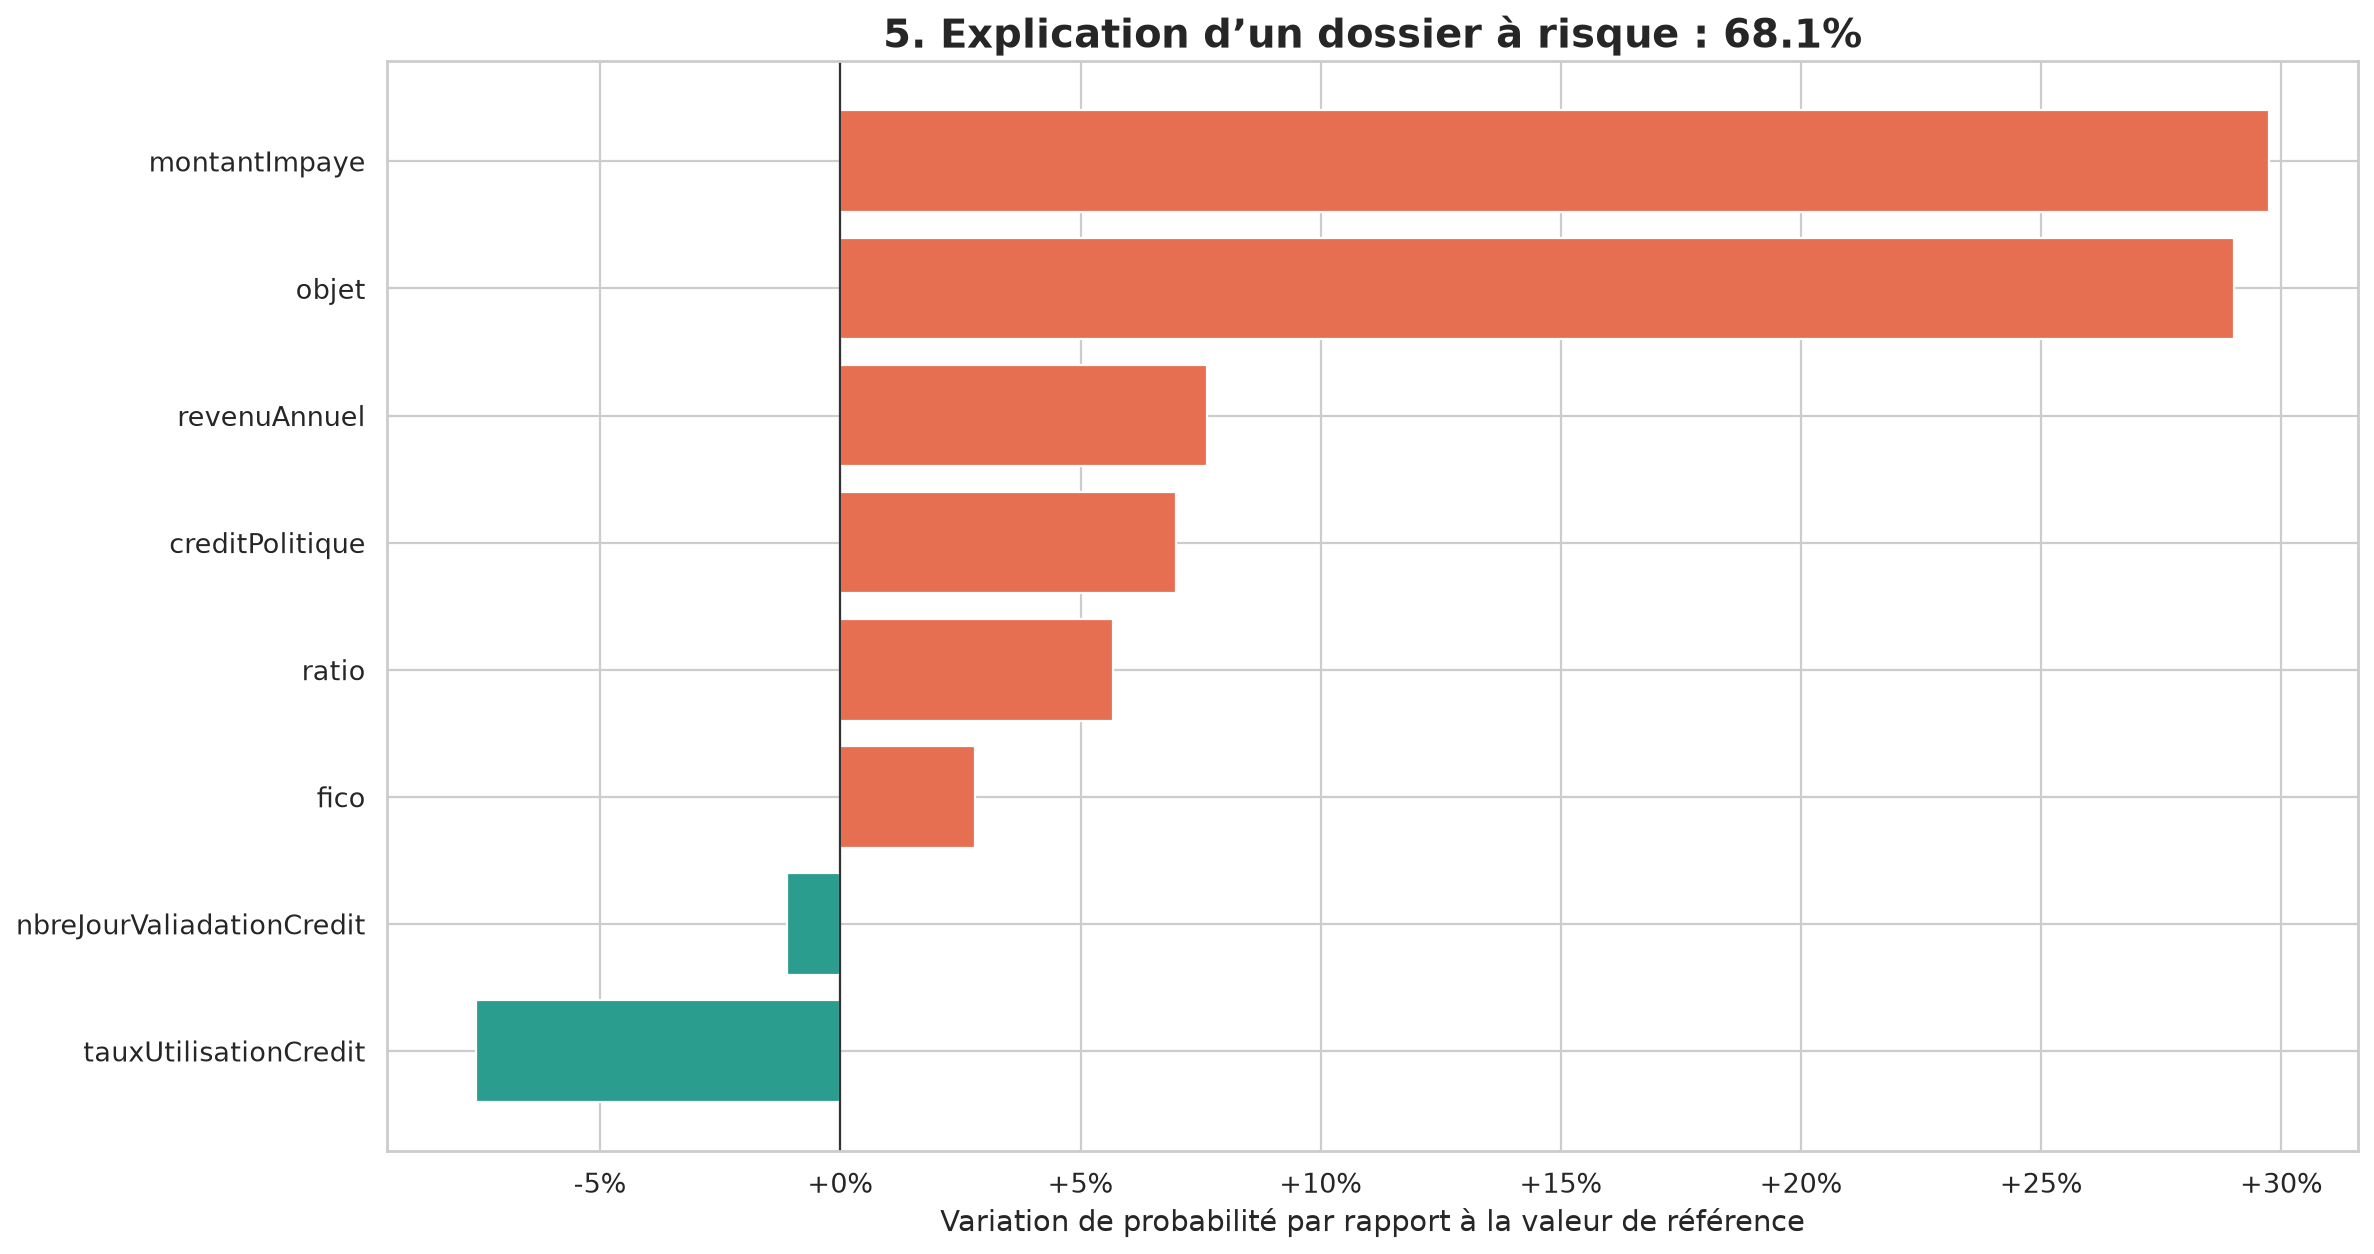

Valeurs observées pour les variables les plus contributives :
                 variable valeur_dossier contribution
            montantImpaye         374487       +0.297
                    objet small_business       +0.290
             revenuAnnuel       12.94801       +0.076
    tauxUtilisationCredit           89.6       -0.076
          creditPolitique              0       +0.070
                    ratio           8.76       +0.057
                     fico            682       +0.028
nbreJourValiadationCredit    5009.958333       -0.011


In [ ]:
risk_position = int(np.argmax(y_proba))
case = X_test.iloc[[risk_position]].copy()
case_probability = float(y_proba[risk_position])

reference = {}
for feature in X_train.columns:
    if feature in numeric_features:
        reference[feature] = X_train[feature].median()
    else:
        reference[feature] = X_train[feature].mode(dropna=True).iloc[0]

contributions = []
for feature in X_test.columns:
    counterfactual = case.copy()
    counterfactual[feature] = reference[feature]
    counterfactual_probability = float(model.predict_proba(counterfactual)[:, 1][0])
    contributions.append({
        "variable": feature,
        "contribution": case_probability - counterfactual_probability,
        "valeur_dossier": case.iloc[0][feature],
    })

local = pd.DataFrame(contributions)
local["abs_contribution"] = local["contribution"].abs()
local_plot = local.nlargest(8, "abs_contribution").sort_values("contribution")
colors = ["#e76f51" if value > 0 else "#2a9d8f" for value in local_plot["contribution"]]

fig, ax = plt.subplots(figsize=(15, 8))
ax.barh(local_plot["variable"], local_plot["contribution"], color=colors)
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title(f"5. Explication d’un dossier à risque : {case_probability:.1%}", fontsize=18, fontweight="bold")
ax.set_xlabel("Variation de probabilité par rapport à la valeur de référence", fontsize=13)
ax.set_ylabel("")
ax.tick_params(axis="both", labelsize=12)
ax.xaxis.set_major_formatter(lambda value, position: f"{value:+.0%}")
plt.tight_layout()
plt.show()

print("Valeurs observées pour les variables les plus contributives :")
print(local_plot.sort_values("abs_contribution", ascending=False)[["variable", "valeur_dossier", "contribution"]].to_string(index=False, formatters={"contribution": "{:+.3f}".format}))

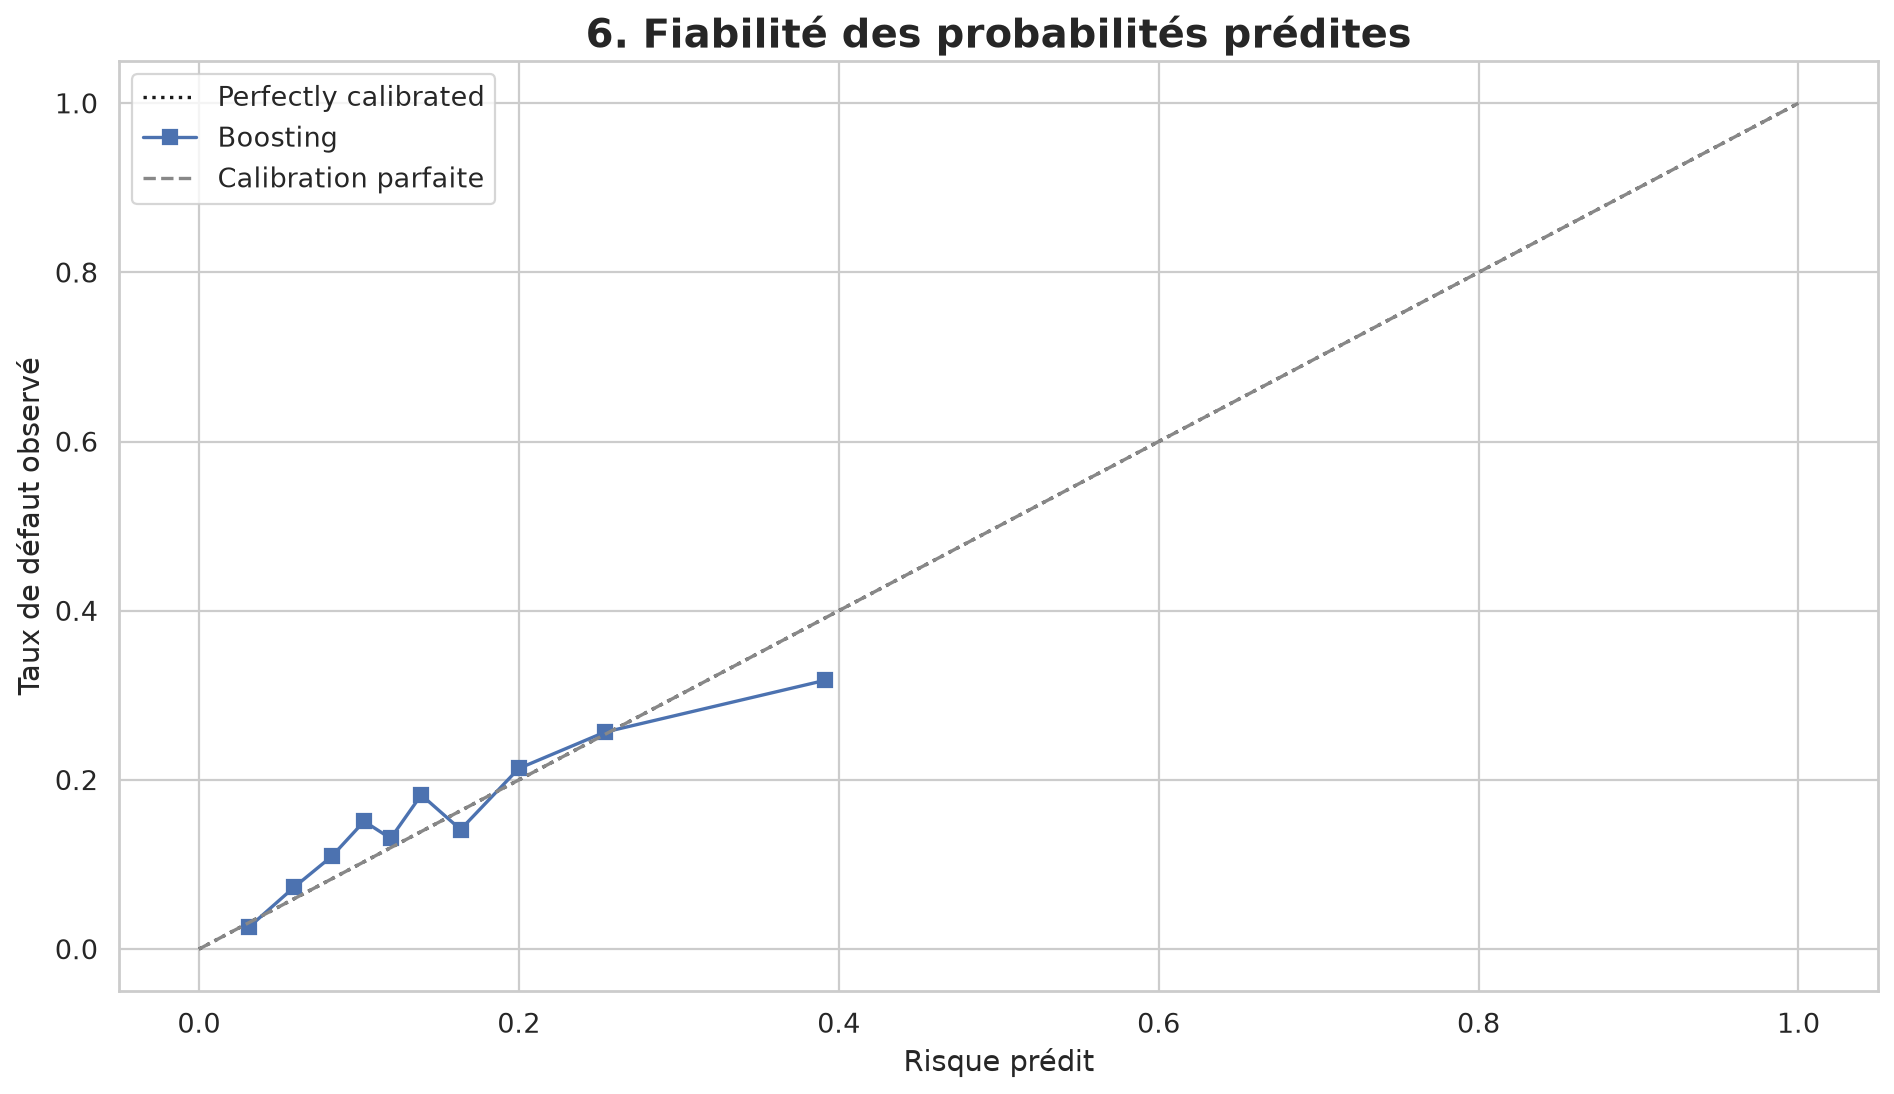

,dossiers,risque_moyen_prevu,taux_defaut_observe
classe_risque,,,
"(0.00603, 0.0471]",192,0.031,0.026
"(0.0471, 0.0722]",192,0.059,0.073
"(0.0722, 0.0941]",191,0.083,0.110
"(0.0941, 0.112]",192,0.103,0.151
"(0.112, 0.129]",191,0.120,0.131
"(0.129, 0.15]",192,0.139,0.182
"(0.15, 0.179]",191,0.164,0.141
"(0.179, 0.222]",192,0.200,0.214
"(0.222, 0.294]",191,0.254,0.257


In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))
CalibrationDisplay.from_predictions(y_test, y_proba, n_bins=10, strategy="quantile", ax=ax, name="Boosting")
ax.plot([0, 1], [0, 1], "--", color="#888888", label="Calibration parfaite")
ax.set_title("6. Fiabilité des probabilités prédites", fontsize=18, fontweight="bold")
ax.set_xlabel("Risque prédit", fontsize=13)
ax.set_ylabel("Taux de défaut observé", fontsize=13)
ax.tick_params(axis="both", labelsize=12)
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

calibration_table = pd.DataFrame({"risque_prevu": y_proba, "defaut_observe": y_test.to_numpy()})
calibration_table["classe_risque"] = pd.qcut(calibration_table["risque_prevu"], q=10, duplicates="drop")
calibration_table.groupby("classe_risque", observed=True).agg(
    dossiers=("risque_prevu", "size"),
    risque_moyen_prevu=("risque_prevu", "mean"),
    taux_defaut_observe=("defaut_observe", "mean"),
).round(3)

## Conclusion

Le modèle repère correctement une partie des dossiers risqués et fournit des explications compréhensibles. Les dossiers les plus risqués sont surtout associés à un montant impayé élevé, à certains objets de prêt et à des indicateurs financiers défavorables.

La calibration montre que le classement des dossiers est utile, mais que la probabilité affichée ne doit pas être prise comme une certitude. Le modèle doit donc aider la décision, sans remplacer l’analyse humaine.

description portifilio:
J'ai réalisé Ce projet, il a pour objectif de
• prédire le risque de non-paiement d'un
emprunteur à partir de ses informations financières et de son historique de crédit. Un modèle de machine learning basé sur le gradient boosting est entraîné puis évalué avec plusieurs indicateurs comme la ROC-AUC, la PR-AUC, le rappel et le F1-score.
L'itérêt principal du projet est l'explicabilité.
Les graphiques permettent d'identifier les
variables les plus importantes, d'observer l'effet du revenu et du score FICO, et de comprendre pourquoi un dossier particulier est considéré comme risqué. Le modèle sert donc d'aide à la décision et ne remplace pas
'analyse humaine.
moins
#datascience#machinelearning#dataanalyti